# 03 · Ecuación salarial de Mincer y efecto diploma con inferencia agrupada por UPM

Estimamos el retorno a la educación sobre los ocupados con salario por hora positivo mediante mínimos cuadrados ponderados (`WLS` con `fexp`) y errores agrupados por unidad primaria de muestreo (`cov_type="cluster"`). El tamaño de muestra y el número de UPM se imprimen en la primera celda.

In [1]:
import json
import pandas as pd
from empleo_enemdu.config import DIR_REPORTS

res = json.loads((DIR_REPORTS / "resultados.json").read_text(encoding="utf-8"))
mincer = res["mincer"]
m1 = mincer["modelos"]["m1_base"]
print(f"n = {mincer['n_muestra_mincer']:,} ocupados en {m1['n_upm_clusters']:,} UPM")
filas_m = []
for clave, mod in mincer["modelos"].items():
    esc = mod["coeficientes"]["escolaridad"]
    filas_m.append(
        {
            "clave": clave,
            "modelo": mod["modelo"],
            "n_observaciones": mod["n_observaciones"],
            "r2_ponderado": mod["r2_ponderado"],
            **esc,
        }
    )
pd.DataFrame(filas_m)

n = 138,381 ocupados en 7,780 UPM


,clave,modelo,n_observaciones,r2_ponderado,beta,efecto_porcentual,ee_cluster_upm,ee_ingenuo_wls,razon_ee_cluster_vs_ingenuo,p_valor,ic95_inf,ic95_sup
0,m1_base,1. Mincer clásico (escolaridad + exp + mujer +...,138381,0.2129,0.07085,7.34,0.00167,0.00048,3.51,0.000000e+00,0.06757,0.07413
1,m2_formalidad,2. + Formalidad y afiliación IESS,138381,0.3510,0.04226,4.32,0.00133,0.00047,2.86,1.325803e-221,0.03966,0.04487
2,m3_completo,"3. + Etnia, EF Rama (21) y EF Provincia (24)",138381,0.3932,0.03143,3.19,0.00136,0.00050,2.72,7.747416e-118,0.02876,0.03410
3,m4_sector_formal,4. Submuestra Sector Formal,77133,0.2198,0.07385,7.66,0.00189,0.00055,3.45,0.000000e+00,0.07014,0.07757
4,m5_sector_informal,5. Submuestra Sector Informal,53941,0.0732,0.02142,2.17,0.00214,0.00084,2.53,1.326455e-23,0.01723,0.02562


## 1. Canal de formalidad y subestimación de los errores ingenuos

* `razon_ee_cluster_vs_ingenuo` mide cuánto subestima el error estándar ignorar el agrupamiento por UPM.
* Al añadir informalidad y afiliación al IESS (`m2_formalidad`) el retorno por año baja; la celda siguiente calcula qué parte del retorno bruto se asocia al acceso a empleo formal.
* `m4_sector_formal` y `m5_sector_informal` estiman el retorno por separado en cada sector.

In [2]:
b1 = mincer["modelos"]["m1_base"]["coeficientes"]["escolaridad"]["beta"]
b2 = mincer["modelos"]["m2_formalidad"]["coeficientes"]["escolaridad"]["beta"]
print(f"Parte del retorno bruto asociada a la formalidad: {(b1 - b2) / b1:.1%}")
pd.DataFrame(
    [
        {"termino": k, **v}
        for k, v in mincer["modelos"]["m2_formalidad"]["coeficientes"].items()
    ]
)

Parte del retorno bruto asociada a la formalidad: 40.4%


,termino,beta,efecto_porcentual,ee_cluster_upm,ee_ingenuo_wls,razon_ee_cluster_vs_ingenuo,p_valor,ic95_inf,ic95_sup
0,escolaridad,0.04226,4.32,0.00133,0.00047,2.86,1.325803e-221,0.03966,0.04487
1,experiencia,0.01898,1.92,0.00080,0.00033,2.43,1.412771e-124,0.01741,0.02054
2,experiencia_cuad,-0.02666,-2.63,0.00160,0.00056,2.87,2.986241e-62,-0.02979,-0.02352
3,mujer,-0.16901,-15.55,0.00829,0.00313,2.65,2.311755e-92,-0.18526,-0.15276
4,rural,-0.09302,-8.88,0.01388,0.00351,3.96,2.088158e-11,-0.12023,-0.06581
5,informal,-0.38309,-31.83,0.01216,0.00366,3.32,5.686836e-218,-0.40692,-0.35927
6,afiliado_seguro,0.30257,35.33,0.01119,0.00364,3.07,4.400919e-161,0.28064,0.32449


## 2. Efecto diploma (*sheepskin effect*) por credencial alcanzada

Sustituyendo los años lineales por niveles credenciales (controlando por experiencia, sexo, área, etnia, informalidad y afiliación al IESS), observamos la convexidad del retorno universitario y de posgrado.

In [3]:
pd.DataFrame(mincer["efecto_diploma"])

,nivel,codigo,beta,premio_salarial_pct,ic95_inf_pct,ic95_sup_pct
0,Sin instrucción (referencia),1_Sin_instruccion,0.0000,0.00,0.00,0.00
1,Educación Básica / Primaria,2_Basica_Primaria,0.0542,5.57,-1.78,13.46
2,Bachillerato / Secundaria,3_Bachillerato_Secundaria,0.1553,16.80,8.65,25.56
3,Superior Técnica / Tecnológica,4_Superior_Tecnica,0.3817,46.47,35.30,58.57
4,Superior Universitaria,5_Superior_Universitaria,0.4699,59.98,48.43,72.44
5,Posgrado (Maestría / PhD),6_Posgrado,0.9480,158.05,136.82,181.19


## 3. Figura: retorno por formalidad y efecto diploma

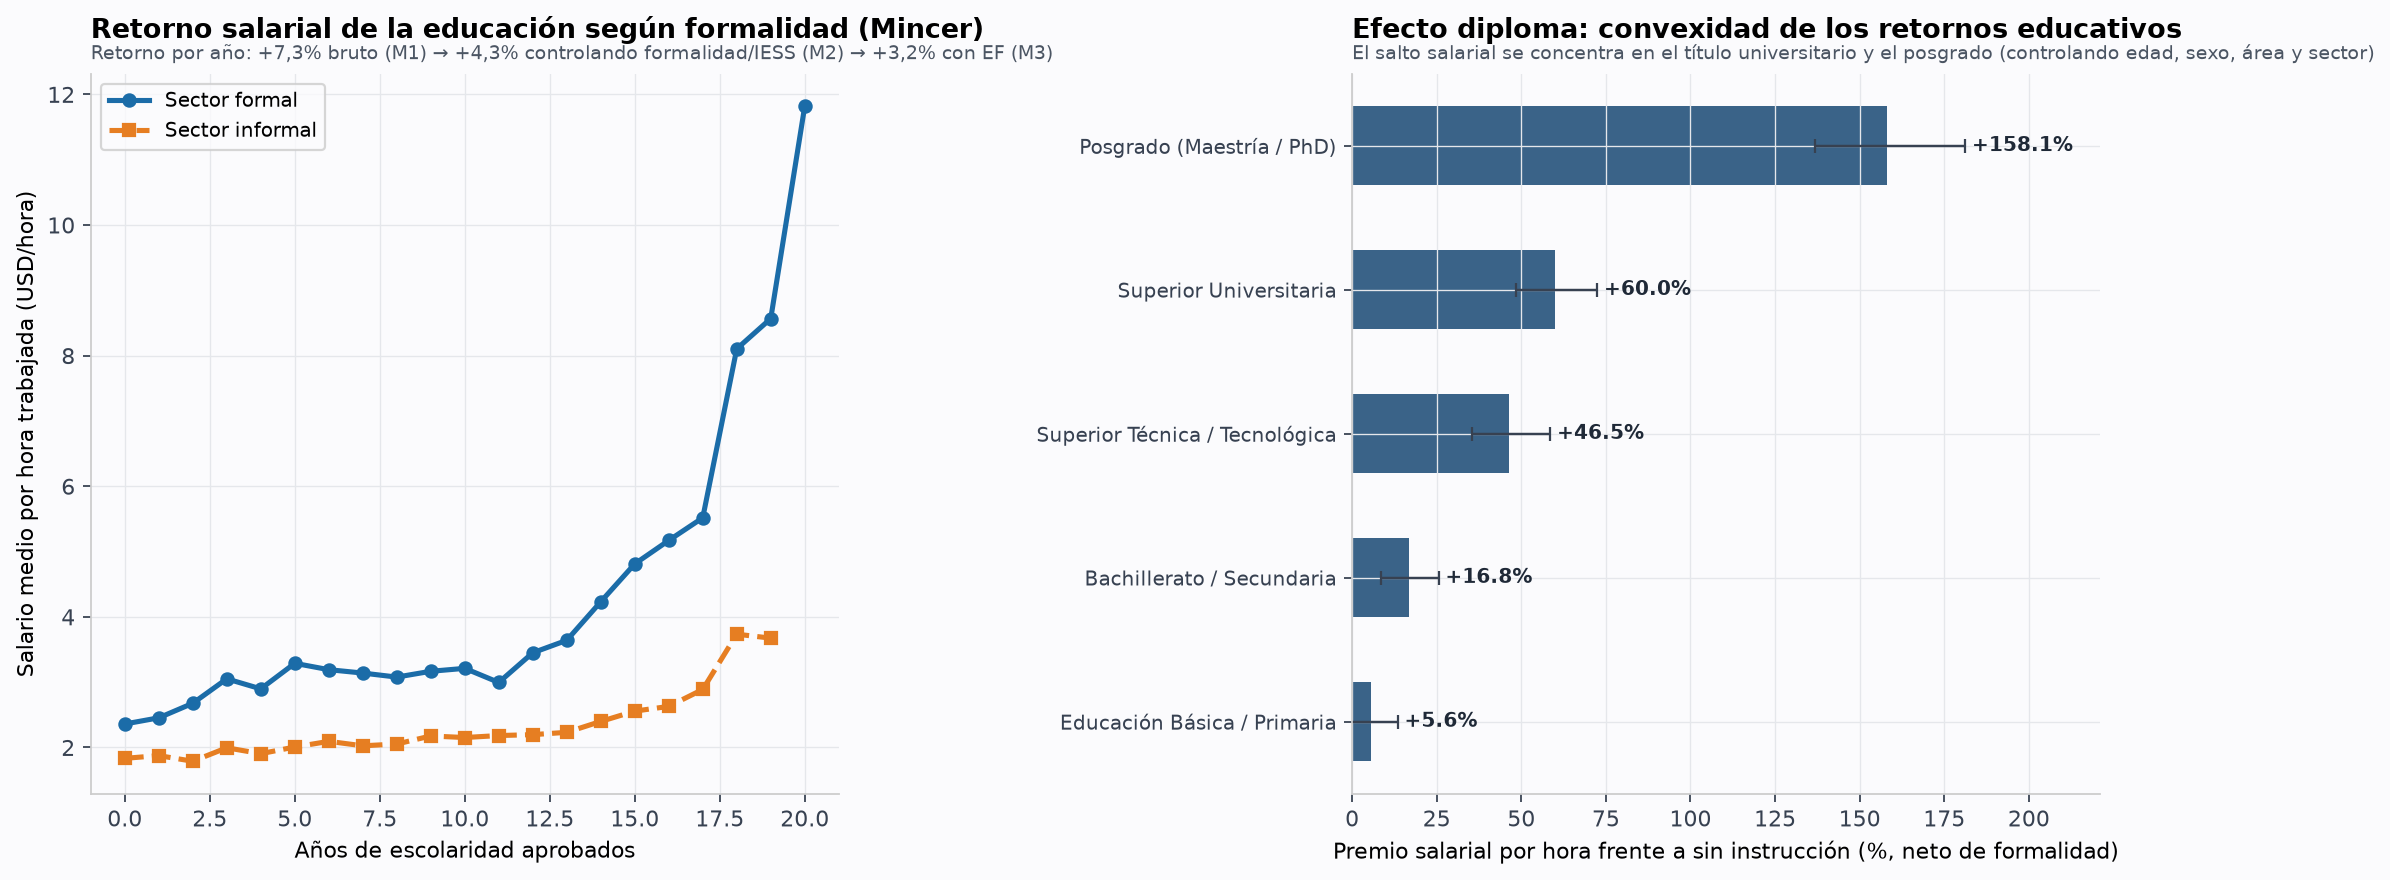

In [4]:
import tempfile
from pathlib import Path
from IPython.display import Image, display
from empleo_enemdu import graficos

# Las figuras se regeneran aquí desde los datos (en una carpeta temporal) y se muestran en línea
DIR_TMP = Path(tempfile.mkdtemp())

display(Image(filename=graficos.fig_07_ecuacion_mincer_y_efecto_diploma(mincer, DIR_TMP)))